In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
  p = Path(img_dir)
  img_list = []
  for folder in p.glob('*'):
      label = folder.name
      for file in folder.glob('*.jpg'):
        img = cv2.imread(str(file))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_list.append((img, label))
  return img_list

train_dir = "/content/drive/MyDrive/Colab Notebooks/datasets/images/images/training/"
test_dir  = "/content/drive/MyDrive/Colab Notebooks/datasets/images/images/test"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

In [8]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256,256)):
  return cv2.resize(img, size)

def label_encoder(label):
  return 1 if label == 'day' else 0

def preprocess(img_list):
  X = []
  y = []
  for img, label in img_list:
    img_std = resize_image(img)
    X.append(img_std)
    y.append(label_encoder(label))
  return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

In [9]:
# Extract HOG features
def extract_hog(X_imgs):
  feats = []
  for img in X_imgs:
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    hog_feat = hog(gray,
                    orientations=9,
                    pixels_per_cell=(8,8),
                    cells_per_block=(2,2),
                    block_norm='L2-Hys',
                    visualize=False,
                    feature_vector=True)
    feats.append(hog_feat)
  return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

In [10]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

In [11]:
X_train, X_val, y_train, y_val = train_test_split(
  X_train_scaled, y_train,
  test_size=0.2,
  random_state=42
)

# Convert labels to numpy arrays
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

In [12]:
input_dim = X_train.shape[1]

model = models.Sequential([
  layers.Input(shape=(input_dim,)),
  layers.Dense(128, activation='relu'),
  layers.Dense(64, activation='relu'),
  layers.Dense(1, activation='sigmoid')
])

model.compile(
  optimizer='adam',
  loss='binary_crossentropy',
  metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(
  X_train, y_train,
  epochs=20,
  batch_size=32,
  validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.8594 - loss: 0.3581 - val_accuracy: 0.9167 - val_loss: 0.4048
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9792 - loss: 0.2195 - val_accuracy: 0.9792 - val_loss: 0.0320
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 1.0000 - loss: 0.0042 - val_accuracy: 0.9792 - val_loss: 0.0459
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 1.0000 - loss: 6.2275e-05 - val_accuracy: 0.9792 - val_loss: 0.0709
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 1.0000 - loss: 9.9832e-06 - val_accuracy: 0.9792 - val_loss: 0.1004
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 1.0000 - loss: 9.4526e-06 - val_accuracy: 0.9583 - val_loss: 0.1386
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 1.0000 - loss: 3.2914e-05 - val_accuracy: 0.9583 - val_loss: 0.1603
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 1.0000 - loss: 4.6307e-05 - val_accuracy: 0.958

In [14]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Test Accuracy:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8438 - loss: 1.8144
Test Accuracy: 0.84375


In [15]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
              precision    recall  f1-score   support

           0       0.79      0.94      0.86        80
           1       0.92      0.75      0.83        80

    accuracy                           0.84       160
   macro avg       0.86      0.84      0.84       160
weighted avg       0.86      0.84      0.84       160

[[75  5]
 [20 60]]


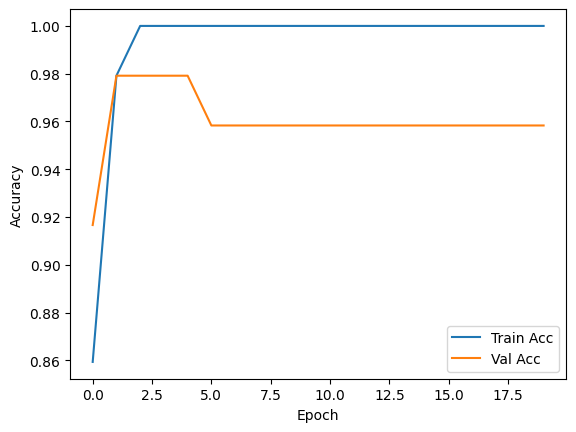

In [16]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [17]:
# SAVE MODEL
model.save('day_night_classifier_model.h5')